## Analyse des défauts de payement
"Le mois prochain sera t il en retard de payement ?"

### Imports

In [43]:
import sklearn
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
print(os.getcwd())

/Users/antoinecollet/Documents/ecole/Universite/MAS/M2/Projet tuteure/Projet_ML/src/projet_ml


In [58]:
df = pd.read_csv("data/UCI_Credit_Card.csv")
print(df.head())
df.isnull().sum()
df.apply(pd.Series.value_counts)
df.describe()

   ID  LIMIT_BAL  SEX  EDUCATION  MARRIAGE  AGE  PAY_0  PAY_2  PAY_3  PAY_4  \
0   1    20000.0    2          2         1   24      2      2     -1     -1   
1   2   120000.0    2          2         2   26     -1      2      0      0   
2   3    90000.0    2          2         2   34      0      0      0      0   
3   4    50000.0    2          2         1   37      0      0      0      0   
4   5    50000.0    1          2         1   57     -1      0     -1      0   

   ...  BILL_AMT4  BILL_AMT5  BILL_AMT6  PAY_AMT1  PAY_AMT2  PAY_AMT3  \
0  ...        0.0        0.0        0.0       0.0     689.0       0.0   
1  ...     3272.0     3455.0     3261.0       0.0    1000.0    1000.0   
2  ...    14331.0    14948.0    15549.0    1518.0    1500.0    1000.0   
3  ...    28314.0    28959.0    29547.0    2000.0    2019.0    1200.0   
4  ...    20940.0    19146.0    19131.0    2000.0   36681.0   10000.0   

   PAY_AMT4  PAY_AMT5  PAY_AMT6  default.payment.next.month  
0       0.0       0.0   

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,...,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000
mean,15000.500000,167484.322667,1.603733,1.853133,1.551867,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,...,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567,0.221200
std,8660.398374,129747.661567,0.489129,0.790349,0.521970,9.217904,1.123802,1.197186,1.196868,1.169139,...,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775,0.415062
min,1.000000,10000.000000,1.000000,0.000000,0.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,...,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000
25%,7500.750000,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000,0.000000
50%,15000.500000,140000.000000,2.000000,2.000000,2.000000,34.000000,0.000000,0.000000,0.000000,0.000000,...,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000,0.000000
75%,22500.250000,240000.000000,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,...,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000,0.000000
max,30000.000000,1000000.000000,2.000000,6.000000,3.000000,79.000000,8.000000,8.000000,8.000000,8.000000,...,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000,1.000000


In [ ]:
print(df.columns)

- PAY_ : Nombre de moi de retard pour le payment du mois 
- BILL_AMT : montant du paiement de la facture 
- PAY_AMT : Montant du paiement précédent
- LIMIT_BAL : Montant du crédit

In [53]:

df['default.payment.next.month'].value_counts(normalize=True)

default.payment.next.month
0    0.7788
1    0.2212
Name: proportion, dtype: float64

In [60]:
cols = df.filter(regex='^PAY_\d+').columns
mask = df[cols].isin([-2, 0]).any(axis=1)

# Comparer le taux de mauvais payeurs (cible_prochain_mois)
print("Taux pour ceux qui ont -2 ou 0 :", df[mask]['default.payment.next.month'].mean())
print("Taux pour les autres :", df[~mask]['default.payment.next.month'].mean())

Taux pour ceux qui ont -2 ou 0 : 0.2004317822583754
Taux pour les autres : 0.35385373060822456


<>:1: SyntaxWarning: invalid escape sequence '\d'
<>:1: SyntaxWarning: invalid escape sequence '\d'
/var/folders/06/1xgj5l5s2kj2hnq3g6lk7fcw0000gn/T/ipykernel_8751/2880670769.py:1: SyntaxWarning: invalid escape sequence '\d'
  cols = df.filter(regex='^PAY_\d+').columns


On voit don que les valeurs de -2 et 0 sont des meilleur payeur, on va don utilisé -1 pour les regouper

In [ ]:
cols = df.filter(regex='^PAY_\d+').columns
df[cols] = df[cols].replace([-2, 0], -1)


<>:1: SyntaxWarning: invalid escape sequence '\d'
<>:1: SyntaxWarning: invalid escape sequence '\d'
/var/folders/06/1xgj5l5s2kj2hnq3g6lk7fcw0000gn/T/ipykernel_8751/1650375298.py:1: SyntaxWarning: invalid escape sequence '\d'
  cols = df.filter(regex='^PAY_\d+').columns


On a un déséquilibre dans les données, on a seulement 22% des individus qui sont des mauvais payeur pour le prochain mois

<>:1: SyntaxWarning: invalid escape sequence '\d'
<>:1: SyntaxWarning: invalid escape sequence '\d'
/var/folders/06/1xgj5l5s2kj2hnq3g6lk7fcw0000gn/T/ipykernel_8751/3236493714.py:1: SyntaxWarning: invalid escape sequence '\d'
  df['moyenne_pay'] = df.filter(regex='^PAY_\d+').mean(axis=1)


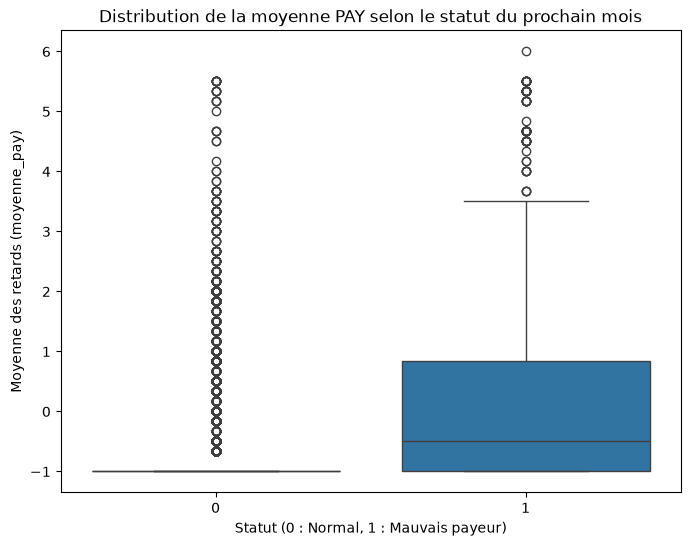

In [56]:
df['moyenne_pay'] = df.filter(regex='^PAY_\d+').mean(axis=1)

# Boxplot pour comparer la moyenne PAY selon le statut (0 = bon payeur, 1 = mauvais payeur)
plt.figure(figsize=(8, 6))
sns.boxplot(x='default.payment.next.month', y='moyenne_pay', data=df)

plt.title("Distribution de la moyenne PAY selon le statut du prochain mois")
plt.xlabel("Statut (0 : Normal, 1 : Mauvais payeur)")
plt.ylabel("Moyenne des retards (moyenne_pay)")
plt.show()

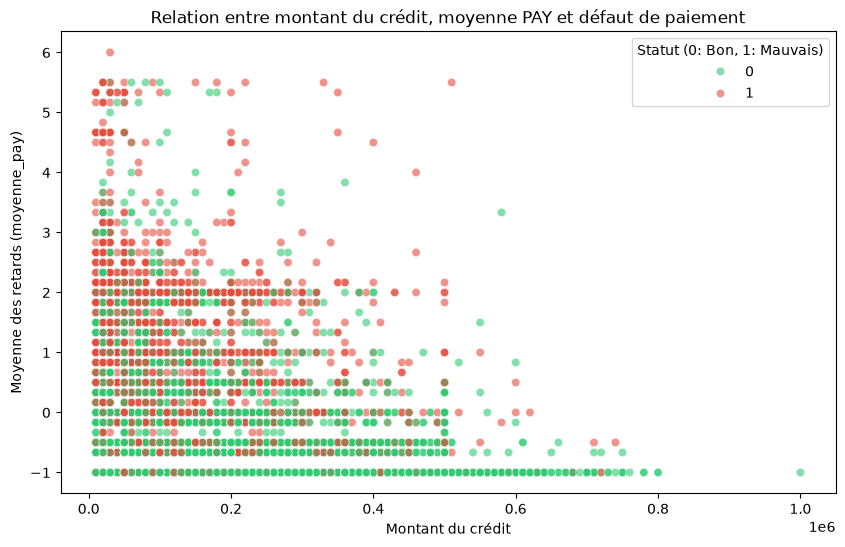

In [57]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='LIMIT_BAL', 
    y='moyenne_pay', 
    hue='default.payment.next.month', 
    data=df, 
    alpha=0.6,
    palette={0: '#2ecc71', 1: '#e74c3c'})  # 0 : Vert (bon), 1 : Rouge (mauvais))

plt.title("Relation entre montant du crédit, moyenne PAY et défaut de paiement")
plt.xlabel("Montant du crédit")
plt.ylabel("Moyenne des retards (moyenne_pay)")
plt.legend(title="Statut (0: Bon, 1: Mauvais)")
plt.show()

On obersve une relation decroissante entre le montant du crédit et le nombre de mois de retard dans les payments et on observe toujours que les prochains retard de payements sont corrélé avec la moyenne des précédents. 
Sur les montants plus faibles les individus se sentent moins préssé ?
Trop de petits prets accordé aux mauvais payeurs ? 